# 02 — Customer Feature Engineering

Convert transaction-level records into one row per customer.

Features include RFM, customer lifetime, product diversity, purchase intervals, weekend behavior and monthly order behavior.


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ml.feature_engineering import create_customer_features

TX = ROOT / "data" / "processed" / "transactions.csv"
OUT = ROOT / "data" / "processed" / "customer_features.csv"

if not TX.exists():
    raise FileNotFoundError("Run `python ml/preprocessing.py` first.")

df = pd.read_csv(TX, parse_dates=["InvoiceDate"])
print(df.shape)


(793609, 10)


In [2]:

customer_features = create_customer_features(df)
display(customer_features.head())
print("Customer count:", len(customer_features))


,CustomerID,first_purchase,last_purchase,frequency,monetary,total_quantity,unique_products,country_count,recency,customer_lifetime,...,items_per_order,avg_purchase_interval,median_purchase_interval,max_purchase_interval,weekend_purchase_ratio,active_months,avg_monthly_orders,max_monthly_orders,avg_monthly_revenue,max_monthly_revenue
0,12346,2009-12-14 08:34:00,2011-01-18 10:01:00,12,77556.46,74285,27,1,326,400,...,6190.416667,35.909091,7.0,203.0,0.000000,5,2.4,5,15511.2920,77183.60
1,12347,2010-10-31 14:20:00,2011-12-07 15:52:00,8,5633.32,3286,126,1,2,402,...,410.750000,57.000000,53.0,90.0,0.158103,8,1.0,1,704.1650,1423.58
2,12348,2010-09-27 14:59:00,2011-09-25 13:13:00,5,2019.40,2714,25,1,75,362,...,542.800000,90.500000,75.0,173.0,0.058824,5,1.0,1,403.8800,892.80
3,12349,2010-04-29 13:20:00,2011-11-21 09:51:00,4,4428.69,1624,138,1,19,570,...,406.000000,189.666667,162.0,389.0,0.000000,4,1.0,1,1107.1725,1757.55
4,12350,2011-02-02 16:01:00,2011-02-02 16:01:00,1,334.40,197,17,1,310,0,...,197.000000,71.627778,55.0,151.0,0.000000,1,1.0,1,334.4000,334.40


Customer count: 5878


In [3]:

display(customer_features.describe().T)


,count,mean,min,25%,50%,75%,max,std
CustomerID,5878.0,15315.313542,12346.0,13833.25,15314.5,16797.75,18287.0,1715.572666
first_purchase,5878,2010-08-22 06:57:33.297039616,2009-12-01 07:45:00,2010-02-09 14:01:15,2010-06-27 13:31:30,2011-01-30 14:30:15,2011-12-09 12:16:00,NaN
last_purchase,5878,2011-05-22 16:19:59.469207296,2009-12-01 09:55:00,2010-11-25 10:24:45,2011-09-05 11:59:00,2011-11-14 11:31:15,2011-12-09 12:50:00,NaN
frequency,5878.0,6.289384,1.0,1.0,3.0,7.0,398.0,13.009406
monetary,5878.0,3008.754787,2.95,345.115,887.39,2298.005,608821.65,14731.924115
total_quantity,5878.0,1815.512249,1.0,189.0,487.0,1369.0,367193.0,8958.973237
unique_products,5878.0,81.989112,1.0,19.0,45.0,103.0,2550.0,116.484552
country_count,5878.0,1.002212,1.0,1.0,1.0,1.0,2.0,0.04698
recency,5878.0,201.331916,1.0,26.0,96.0,380.0,739.0,209.338707
customer_lifetime,5878.0,273.022457,0.0,0.0,220.5,511.0,738.0,258.807591


In [4]:

numeric = customer_features.select_dtypes(include=np.number)
missing = numeric.isna().sum().sort_values(ascending=False).to_frame("missing")
missing["missing_pct"] = missing["missing"] / len(customer_features) * 100
display(missing[missing["missing"] > 0])


,missing,missing_pct


In [5]:

feature_cols = [
    "recency", "frequency", "monetary", "average_order_value",
    "customer_lifetime", "total_quantity", "unique_products",
    "avg_purchase_interval", "median_purchase_interval",
    "max_purchase_interval", "weekend_purchase_ratio",
    "active_months", "avg_monthly_orders", "max_monthly_orders"
]
available = [c for c in feature_cols if c in customer_features.columns]
display(customer_features[available].describe().T)


,count,mean,std,min,25%,50%,75%,max
recency,5878.0,201.331916,209.338707,1.00,26.00000,96.000000,380.000000,739.000
frequency,5878.0,6.289384,13.009406,1.00,1.00000,3.000000,7.000000,398.000
monetary,5878.0,3008.754787,14731.924115,2.95,345.11500,887.390000,2298.005000,608821.650
average_order_value,5878.0,389.992445,1215.007989,2.95,179.45000,283.608333,419.670000,84236.250
customer_lifetime,5878.0,273.022457,258.807591,0.00,0.00000,220.500000,511.000000,738.000
total_quantity,5878.0,1815.512249,8958.973237,1.00,189.00000,487.000000,1369.000000,367193.000
unique_products,5878.0,81.989112,116.484552,1.00,19.00000,45.000000,103.000000,2550.000
avg_purchase_interval,5878.0,93.310270,84.613048,0.00,50.03125,71.627778,100.750000,714.000
median_purchase_interval,5878.0,81.745407,87.581686,0.00,37.00000,55.000000,86.000000,714.000
max_purchase_interval,5878.0,167.894182,104.924754,0.00,106.00000,151.000000,203.000000,714.000


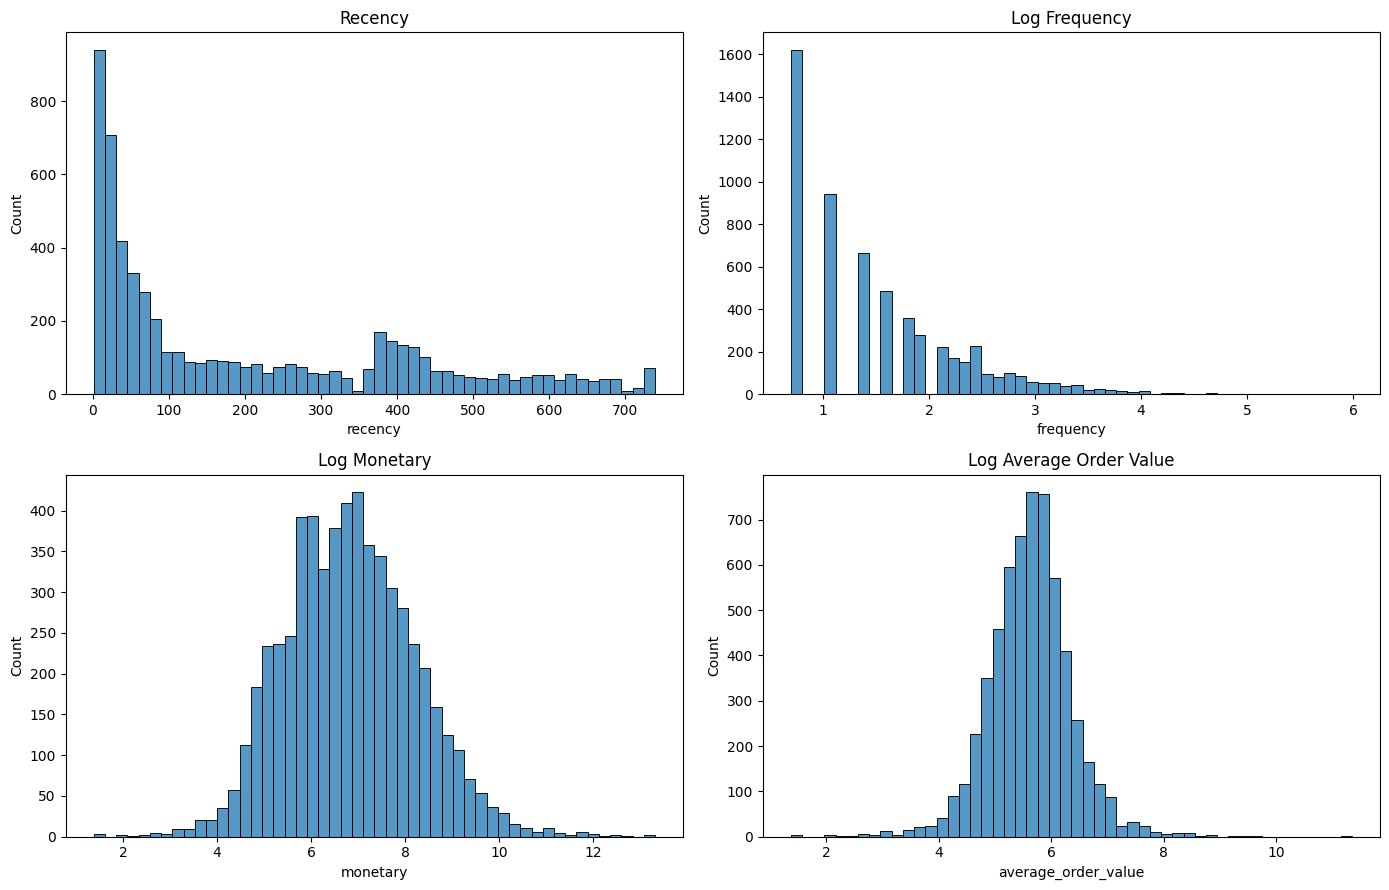

In [6]:

fig, axes = plt.subplots(2, 2, figsize=(14,9))

sns.histplot(customer_features["recency"], bins=50, ax=axes[0,0])
axes[0,0].set_title("Recency")

sns.histplot(np.log1p(customer_features["frequency"]), bins=50, ax=axes[0,1])
axes[0,1].set_title("Log Frequency")

sns.histplot(np.log1p(customer_features["monetary"]), bins=50, ax=axes[1,0])
axes[1,0].set_title("Log Monetary")

sns.histplot(np.log1p(customer_features["average_order_value"]), bins=50, ax=axes[1,1])
axes[1,1].set_title("Log Average Order Value")

plt.tight_layout()
plt.show()


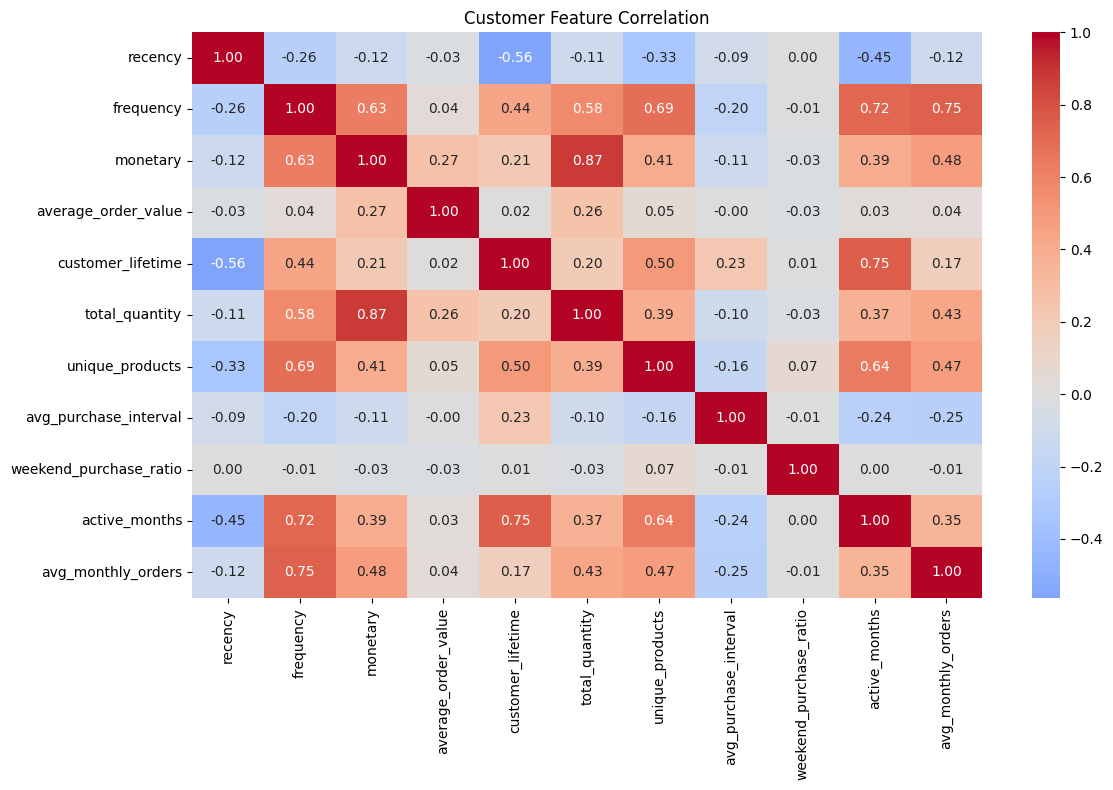

In [7]:

corr_cols = [c for c in [
    "recency", "frequency", "monetary", "average_order_value",
    "customer_lifetime", "total_quantity", "unique_products",
    "avg_purchase_interval", "weekend_purchase_ratio",
    "active_months", "avg_monthly_orders"
] if c in customer_features.columns]

plt.figure(figsize=(12,8))
sns.heatmap(customer_features[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Customer Feature Correlation")
plt.tight_layout()
plt.show()


In [8]:

customer_features.to_csv(OUT, index=False)
print("Saved:", OUT)
print("Shape:", customer_features.shape)


Saved: c:\Users\satya\OneDrive\Documents\Customer Intelligence Platform\data\processed\customer_features.csv
Shape: (5878, 21)


## Interpretation

Inspect skew, outliers, purchase intervals and correlations before clustering.

The production segmentation pipeline applies log transforms and standardization before clustering.
